### 高价格 低溢价

In [3]:
import os, datetime, traceback, shutil, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams

In [4]:
import akshare as ak

d:\software\python\python38\lib\site-packages\akshare\__init__.py:2645: UserWarning: 为了支持更多特性，请将 Python 升级到 3.9 及以上版本！
  warnings.warn(


In [5]:
plt.rcParams['figure.figsize'] = [12, 6]

In [6]:
rcParams['font.family'] = 'SimHei'

In [7]:
from lutils.stock import LTdxHq

In [8]:
%matplotlib inline

In [9]:
bond_zh_cov_info_ths_df = ak.bond_zh_cov_info_ths()
bond_zh_cov_df = ak.bond_zh_cov()

In [10]:
bond_zh_cov_info_ths_df.head(2)

,债券代码,债券简称,申购日期,申购代码,原股东配售码,每股获配额,计划发行量,实际发行量,中签公布日,中签号,上市日期,正股代码,正股简称,转股价格,到期时间,中签率
0,123238,卡倍转02,2024-01-11,370863,380863,5.9518,5.29,5.29,2024-01-15,532264、032264、157264、282264、407264、657264、7822...,NaT,300863,卡倍亿,49.01,2030-01-11,0.00081660
1,123237,佳禾转债,2024-01-04,370793,380793,2.9670,10.04,10.04,2024-01-08,71389、21389、46389、96389；\r\n246337、746337；\r\n...,NaT,300793,佳禾智能,21.75,2030-01-04,0.00423126


In [11]:
bond_zh_cov_df.head(2)

,债券代码,债券简称,申购日期,申购代码,申购上限,正股代码,正股简称,正股价,转股价,转股价值,债现价,转股溢价率,原股东配售-股权登记日,原股东配售-每股配售额,发行规模,中签号发布日,中签率,上市时间
0,123238,卡倍转02,2024-01-11,370863,100,300863,卡倍亿,44.78,49.01,91.3691,100.0,9.45,2024-01-10,5.9518,5.29,2024-01-15,0.000817,NaT
1,123237,佳禾转债,2024-01-04,370793,100,300793,佳禾智能,18.14,21.75,83.3563,100.0,19.97,2024-01-03,2.9670,10.04,2024-01-08,0.004231,NaT


In [12]:
data_root = 'E:/convertible/datas'

In [13]:
def _select_market_code(code):
        code = str(code)
        if code[0] in ['5', '6', '9'] or code[:3] in ["009", "126", "110", "201", "202", "203", "204", '110', '113'] or code[:4] in ['1180'] or code[:5] in ['11100'] or code[:5] in ['11101']:
            return 'sh' # 1
        return 'sz' # 0

In [14]:
ltdxhq = LTdxHq()

In [15]:
def zgj(row):
    try:
        # file_path = 'E:/convertible/d/%s%s.csv' % (market, symbol)
        symbol = row['债券代码']
                
        market = _select_market_code(symbol)
        code = '%s%s' % (market, symbol)
        save_path = os.path.join(data_root, '%s.h5' % code)
        if os.path.exists(save_path):
            print('pass %s' % code)
            return
        
        df = ak.bond_zh_hs_cov_daily(symbol=code)
        if not df.empty:
            df = df[df.date >= pd.to_datetime('2016-01-01').date()]
            df['date'] = pd.to_datetime(df.date)
            # df = pd.read_csv(file_path, index_col=0, parse_dates=['date'])
    
            analysis_df = ak.bond_zh_cov_value_analysis(symbol=symbol)
            analysis_df = analysis_df.rename(columns={
                '日期': 'date2',
                '收盘价': 'shoupajia',
                '纯债价值': 'chunzhaijiazhi',
                '转股价值': 'zhuangujiazhi',
                '纯债溢价率': 'chunzhaiyijialv',
                '转股溢价率': 'zhuanguyijialv',
            })
            analysis_df['date2'] = pd.to_datetime(analysis_df['date2'])
            
            df = df.merge(analysis_df, left_on='date', right_on='date2')
        
            z_symbol = bond_zh_cov_df[bond_zh_cov_df['债券代码'] == symbol]['正股代码'].iloc[0]
           
            start = datetime.datetime.strftime(df['date'].iloc[0], '%Y-%m-%d')
            end = datetime.datetime.strftime(df['date'].iloc[-1], '%Y-%m-%d')
            
            # print(z_symbol)
            ddf = ltdxhq.get_k_data_daily(code=z_symbol, start=start, end=end)
            ddf = ddf.rename(columns={
                'open': 'open_share',
                'close': 'close_share',
                'high': 'high_share',
                'low': 'low_share',
                'volume': 'volume_share',
                'amount': 'amount_share',
            })
            # print(df)
            # print(ddf)
            df = df.merge(ddf, left_on='date', right_index=True)
        
            df['zgj'] = df['close_share'] * 100 / df['zhuangujiazhi']
            # df['yjl'] = df['close'] / df['转股价值'] - 1
    
            # df.to_csv(path_or_buf=save_path)
            df.to_hdf(path_or_buf=save_path, key=code, mode='w', format='table', data_columns=True)
            print(code)
    except:
        print('error %s' % row['债券代码'])
        traceback.print_exc()
        

In [16]:
# zgj({'债券代码': '128100'})

In [17]:
# # bond_zh_cov_df.apply(fetch_by_code, axis=1)
# bond_zh_cov_info_ths_df.apply(zgj, axis=1)

In [18]:
# m_p = 'E:/convertible/'
# for f in os.listdir(data_root):
#     # print('%s %s' % (f, f[2:8] in bond_zh_cov_info_ths_df['债券代码'].values))
#     if not (f[2:8] in bond_zh_cov_info_ths_df['债券代码'].values):
#         print(f)
#         new = os.path.join(m_p, f)
#         old = os.path.join(data_root, f)
#         shutil.move(old, new)

In [19]:
datetime_range = []
dfs = {}

In [20]:
for f in os.listdir(data_root):
    print(f)
    file_path = os.path.join(data_root, f)
    # df = pd.read_csv(file_path, index_col=0, parse_dates=['date'])
    df = pd.read_hdf(file_path)
    dfs[f[:-3]] = df
    start = datetime.datetime.strftime(df['date'].iloc[0], '%Y-%m-%d')
    end = datetime.datetime.strftime(df['date'].iloc[-1], '%Y-%m-%d')

    datetime_range.append([start, end, f])

sh110038.h5
sh110039.h5
sh110040.h5
sh110041.h5
sh110042.h5
sh110043.h5
sh110044.h5
sh110045.h5
sh110046.h5
sh110047.h5
sh110048.h5
sh110049.h5
sh110050.h5
sh110051.h5
sh110052.h5
sh110053.h5
sh110054.h5
sh110055.h5
sh110056.h5
sh110057.h5
sh110058.h5
sh110059.h5
sh110060.h5
sh110061.h5
sh110062.h5
sh110063.h5
sh110064.h5
sh110065.h5
sh110066.h5
sh110067.h5
sh110068.h5
sh110069.h5
sh110070.h5
sh110071.h5
sh110072.h5
sh110073.h5
sh110074.h5
sh110075.h5
sh110076.h5
sh110077.h5
sh110079.h5
sh110080.h5
sh110081.h5
sh110082.h5
sh110083.h5
sh110084.h5
sh110085.h5
sh110086.h5
sh110087.h5
sh110088.h5
sh110089.h5
sh110090.h5
sh110091.h5
sh110092.h5
sh110093.h5
sh110094.h5
sh110095.h5
sh111000.h5
sh111001.h5
sh111002.h5
sh111003.h5
sh111004.h5
sh111005.h5
sh111006.h5
sh111007.h5
sh111008.h5
sh111009.h5
sh111010.h5
sh111011.h5
sh111012.h5
sh111013.h5
sh111014.h5
sh111015.h5
sh111016.h5
sh111017.h5
sh113011.h5
sh113012.h5
sh113013.h5
sh113014.h5
sh113015.h5
sh113016.h5
sh113017.h5
sh113018.h5
sh11

In [21]:
# ltdxhq = LTdxHq()

In [22]:
# df_399413 = ltdxhq.get_k_data_daily(code='399413', start='2017-01-01', count=1, qfq=False)

In [23]:
df_399413_dir = os.path.join('E:/convertible', 'sz399413.h5')

In [24]:
df_399413 = pd.read_hdf(df_399413_dir)

In [26]:
# get_close('sz128041', datetime.datetime.strptime('2019-01-28', '%Y-%m-%d'))

In [27]:
def get_close(code, date):
    # root = 'E:/convertible/datas'
    # file_path = os.path.join(data_root, '%s.csv' % code)
    file_path = os.path.join(data_root, '%s.h5' % code)
    if code in dfs:
        df = dfs[code]
    else:
        # df = pd.read_csv(file_path, index_col=0, parse_dates=['date'])
        df = pd.read_hdf(file_path)
        dfs[code] = df
    # print(df['date'].values)
    # print(pd.to_datetime(date) in df['date'].values)
    if pd.to_datetime(date) in df['date'].values:
        return df[(df['date'] == date)]['close'].iloc[0] #  & (df['over'] > date)
    else:
        return None

In [28]:
def get_pre_close(code, date):
    # file_path = os.path.join(data_root, '%s.csv' % code)
    file_path = os.path.join(data_root, '%s.h5' % code)
    if code in dfs:
        df = dfs[code]
    else:
        # df = pd.read_csv(file_path, index_col=0, parse_dates=['date'])
        df = pd.read_hdf(file_path)
        dfs[code] = df

    return df[(df['date'] < date)]['close'].iloc[-1]

In [29]:
def get_next_close(code, date):
    # file_path = os.path.join(data_root, '%s.csv' % code)
    file_path = os.path.join(data_root, '%s.h5' % code)
    if code in dfs:
        df = dfs[code]
    else:
        # df = pd.read_csv(file_path, index_col=0, parse_dates=['date'])
        df = pd.read_hdf(file_path)
        dfs[code] = df

    return df[(df['date'] > date)]['close'].iloc[0] #  & (df['over'] > date)

In [56]:
def filter_syl(df, position, date):
    '''
    过滤 收盘价 + 溢价率 * 100
    '''
    da = []

    for i, row in df[df['over'] > date].iterrows():
        # file_path = os.path.join(data_root, '%s.csv' % row.code)
        # data_df = pd.read_csv(file_path, index_col=0, parse_dates=['date'])
        if row.code in dfs:
            data_df = dfs[row.code]
        else:
            file_path = os.path.join(data_root, '%s.h5' % row.code)
            data_df = pd.read_hdf(file_path)
            dfs[row.code] = data_df
            
        # print(data_df)
        ddd = data_df[(data_df['date'] == date)]
        # print(ddd)
        if not ddd.empty:
            d = dict(ddd.iloc[-1])
            d['code'] = row.code
            da.append(d)
        else:
            if row.code in position:
                ddd = data_df[(data_df['date'] <= date)]
                if not ddd.empty:
                    d = dict(ddd.iloc[-1])
                    d['code'] = row.code
                    da.append(d)
                

    d = pd.DataFrame(da)
    if not d.empty:
        # print(d)
        d['sort'] = d['close'] + d['zhuanguyijialv'] * 100
        # _d = d
        _d = d[d['close'] < 110]
        _d = _d.sort_values(by=['close', 'zhuanguyijialv'], ascending=[False, True])
        filter_df = _d[5:15]
        filter_codes = filter_df['code'].values

        _a = []
        for p in position:
            try:
                if p not in filter_codes:
                    _a.append(dict(d[d['code'] == p].iloc[0]))
            except Exception as ex:
                print(p, date)
                print('sdf')
                raise
                    
        if len(_a) > 0:
            _df = pd.DataFrame(_a)
            filter_df = pd.concat([filter_df, _df])
        
        return filter_df
    else:
        return pd.DataFrame()

In [57]:
# def aa(date, position):
#     current_date = datetime.datetime.strptime(date, '%Y-%m-%d')
#     trading_df = datetime_df[(datetime_df['start'] < current_date) & (datetime_df['over'] > current_date)]
    
#     syl_df = filter_syl(trading_df, position, current_date)
#     return syl_df

In [58]:
# datetime_range.sort()
# datetime_df = pd.DataFrame(datetime_range, columns=['start', 'end', 'file'])

# datetime_df['start'] = pd.to_datetime(datetime_df['start'])
# datetime_df['end'] = pd.to_datetime(datetime_df['end'])
# datetime_df['market'] = datetime_df.file.str[:2]
# datetime_df['symbol'] = datetime_df.file.str[2:8]
# datetime_df['code'] = datetime_df.file.str[:8]

# datetime_df['over'] = datetime_df['end'] - np.timedelta64(7, 'D')

In [59]:
# ps = ["sz128038", "sh113505", "sz123009", "sz128015", "sh113017", "sh110038", "sh113504", "sz128030", "sz123002", "sh113015", "sz128022", "sh113503", "sz128027", "sz128036", "sz128034", "sz123006", "sh110042", "sz128037", "sh113507"]
# ddddd = aa('2018-05-14', ps)

In [60]:
# ddddd

In [61]:
def bt(datetime_range, q=10, position_count=10, cash=1000000, start_date='2018-01-01', end_date='2024-01-01', min_count=100, over_day=7):
    '''
    min_count 最少可转债数量 达到门槛开始执行策略
    over_day 可转债结束时间 前N天
    
    '''
    position = []
    position_dict = {}
    _cash = cash
    h = 100
    _ind = 100

    high_price = 130
    
    datetime_range.sort()
    datetime_df = pd.DataFrame(datetime_range, columns=['start', 'end', 'file'])

    datetime_df['start'] = pd.to_datetime(datetime_df['start'])
    datetime_df['end'] = pd.to_datetime(datetime_df['end'])
    datetime_df['market'] = datetime_df.file.str[:2]
    datetime_df['symbol'] = datetime_df.file.str[2:8]
    datetime_df['code'] = datetime_df.file.str[:8]
    
    datetime_df['over'] = datetime_df['end'] - np.timedelta64(over_day, 'D')

    start = datetime.datetime.strptime(start_date, '%Y-%m-%d')
    end = datetime.datetime.strptime(end_date, '%Y-%m-%d')

    current_date = start
    with open('E:/convertible/records3.txt', 'w', encoding='utf-8') as f:
        while current_date < end:
            current_date += datetime.timedelta(days=1)
            print('%s %0.2f %s %s' % (datetime.datetime.strftime(current_date, '%Y-%m-%d'), _cash, len(position), _ind)) # 
            
            over_df = datetime_df[datetime_df['over'] == current_date]
            for code in over_df['code'].values: # 退市前7天 取消, 提前计算的 后续修改
                if code in position:
                    # quantity = h # position[code]
                    position.remove(code)
    
                    _cash += h * get_pre_close(code, current_date)
    
            # if current_date.weekday() == 5: # 星期六重新计算持仓
            if current_date.weekday() < 5:
                trading_df = datetime_df[(datetime_df['start'] < current_date) & (datetime_df['over'] > current_date)]
                if trading_df.shape[0] > min_count:
                    syl_df = filter_syl(trading_df, position, current_date)
                    # print(syl_df)
                    if not syl_df.empty:
                        new_array = list(syl_df.code.values)
                        old_array = list(position)
        
                        add_list = list(set(new_array) - set(old_array))
                        # del_list = set(old_array) - set(new_array)
    
                        current_date_str = datetime.datetime.strftime(current_date, '%Y-%m-%d')
                        for a in add_list:
                            price = get_close(a, current_date)
                            _cash -= price * h
    
                            position_dict[a] = _ind + 30
                            
        
                        # for d in del_list:
                        #     price = get_next_close(d, current_date)
                        #     _cash += price * h
                        
                        del_list = []
                        for c in new_array:
                            price = get_close(c, current_date)
                            if price is not None and price > high_price: # position_dict[c]:
                                del_list.append(c)
                                del position_dict[c]
                                _cash += price * h
    
                        position = list(set(new_array) - set(del_list))
                        if len(position) > 50:
                            current_date_syl_df = syl_df[syl_df['date'] == current_date]
                            position_df = current_date_syl_df[(current_date_syl_df.code.isin(position)) & (current_date_syl_df.close > 120)]
                            position_df = position_df.sort_values(by=['close'], ascending=[False])
                            
                            for p in position_df.code.values:
                                del_list.append(p)
                                price = position_df[position_df['code'] == p].close.iloc[0]
                                _cash += price * h
                        position = list(set(position) - set(del_list))
                        
                        f.write('%s %s %s %s %s\n' % (current_date_str, json.dumps(position), json.dumps(add_list), json.dumps(del_list), json.dumps(position_dict)))
    
            position_cash = 0
            prices = []
            pre_prices = []
            for p in position:
                price = get_close(p, current_date)
                # print(price, p)
                if price:
                    fxl = bond_zh_cov_info_ths_df.loc[bond_zh_cov_info_ths_df['债券代码'] == p[2:], '实际发行量'].iloc[0]
                    pre_price = get_pre_close(p, current_date)
                    
                    position_cash += price * h
                    prices.append(price * fxl)
                    pre_prices.append(pre_price * fxl)
    
            if len(prices) > 0:
                # pre_ind = 100
                # if len(inds) > 0:
                #     pre_ind = inds[-1]
                # print('=======================================')
                # print('%s %s\n%s\n%s' % (current_date, position, prices, pre_prices))
                # print('%s %s %s' % (_ind, np.sum(prices), np.sum(pre_prices)))
                
                _ind = _ind * (np.sum(prices) / np.sum(pre_prices))
                # print('=== %s' % _ind)
                inds.append([current_date, _ind]) # np.mean(prices)]
                cashs.append([current_date, _cash + position_cash])

    for p in position:
        price = get_close(p, current_date)
        if price is None:
            price = get_pre_close(p, current_date)
        _cash += price * h

    # print(_cash)
    
    # for i, row in datetime_df.iterrows():
    #     print(row['name'], row['age'])
    

In [62]:
cashs = []
inds = []
bt(datetime_range, start_date='2017-01-01', min_count=50)

2017-01-02 1000000.00 0 100
2017-01-03 1000000.00 0 100
2017-01-04 1000000.00 0 100
2017-01-05 1000000.00 0 100
2017-01-06 1000000.00 0 100
2017-01-07 1000000.00 0 100
2017-01-08 1000000.00 0 100
2017-01-09 1000000.00 0 100
2017-01-10 1000000.00 0 100
2017-01-11 1000000.00 0 100
2017-01-12 1000000.00 0 100
2017-01-13 1000000.00 0 100
2017-01-14 1000000.00 0 100
2017-01-15 1000000.00 0 100
2017-01-16 1000000.00 0 100
2017-01-17 1000000.00 0 100
2017-01-18 1000000.00 0 100
2017-01-19 1000000.00 0 100
2017-01-20 1000000.00 0 100
2017-01-21 1000000.00 0 100
2017-01-22 1000000.00 0 100
2017-01-23 1000000.00 0 100
2017-01-24 1000000.00 0 100
2017-01-25 1000000.00 0 100
2017-01-26 1000000.00 0 100
2017-01-27 1000000.00 0 100
2017-01-28 1000000.00 0 100
2017-01-29 1000000.00 0 100
2017-01-30 1000000.00 0 100
2017-01-31 1000000.00 0 100
2017-02-01 1000000.00 0 100
2017-02-02 1000000.00 0 100
2017-02-03 1000000.00 0 100
2017-02-04 1000000.00 0 100
2017-02-05 1000000.00 0 100
2017-02-06 1000000.0

In [63]:
df_399413.head()

,open,close,high,low,volume,amount
date,,,,,,
2017-01-03,106.03,106.32,106.57,105.98,15348.0,181053872.0
2017-01-04,106.31,106.98,107.00,106.29,20758.0,241999680.0
2017-01-05,106.99,107.04,107.43,106.97,37391.0,432362880.0
2017-01-06,107.09,106.91,107.23,106.82,15639.0,183621856.0
2017-01-09,106.91,107.40,107.41,106.91,27435.0,319914560.0


In [64]:
inds_df = pd.DataFrame(inds, columns=['date', 'ind'])
cashs_df = pd.DataFrame(cashs, columns=['date', 'cash'])

inds_df = inds_df.set_index(pd.to_datetime(inds_df['date']), drop=True, inplace=False)
cashs_df = cashs_df.set_index(pd.to_datetime(cashs_df['date']), drop=True, inplace=False)

In [65]:
inds_cashs_df = inds_df.merge(cashs_df, left_index=True, right_index=True)

In [66]:
inds_cashs_df

,date_x,ind,date_y,cash
date,,,,
2018-04-12,2018-04-12,99.632022,2018-04-12,1000000.0
2018-04-13,2018-04-13,99.406688,2018-04-13,999691.3
2018-04-16,2018-04-16,98.659959,2018-04-16,999008.8
2018-04-17,2018-04-17,98.216383,2018-04-17,998364.4
2018-04-18,2018-04-18,98.349916,2018-04-18,998397.2
...,...,...,...,...
2023-12-25,2023-12-25,119.848616,2023-12-25,1927284.4
2023-12-26,2023-12-26,119.721452,2023-12-26,1922152.7
2023-12-27,2023-12-27,119.961192,2023-12-27,1926974.2


In [67]:
inds_cashs_all_df = inds_cashs_df.merge(df_399413.close, left_index=True, right_index=True)
inds_cashs_all_df['ind_per'] = inds_cashs_all_df['ind'] / inds_cashs_all_df['ind'].iloc[0]
inds_cashs_all_df['close_per'] = inds_cashs_all_df['close'] / inds_cashs_all_df['close'].iloc[0]

In [68]:
inds_cashs_all_df.head()

,date_x,ind,date_y,cash,close,ind_per,close_per
date,,,,,,,
2018-04-12,2018-04-12,99.632022,2018-04-12,1000000.0,111.10,1.000000,1.000000
2018-04-13,2018-04-13,99.406688,2018-04-13,999691.3,110.59,0.997738,0.995410
2018-04-16,2018-04-16,98.659959,2018-04-16,999008.8,109.91,0.990243,0.989289
2018-04-17,2018-04-17,98.216383,2018-04-17,998364.4,109.55,0.985791,0.986049
2018-04-18,2018-04-18,98.349916,2018-04-18,998397.2,110.61,0.987132,0.995590


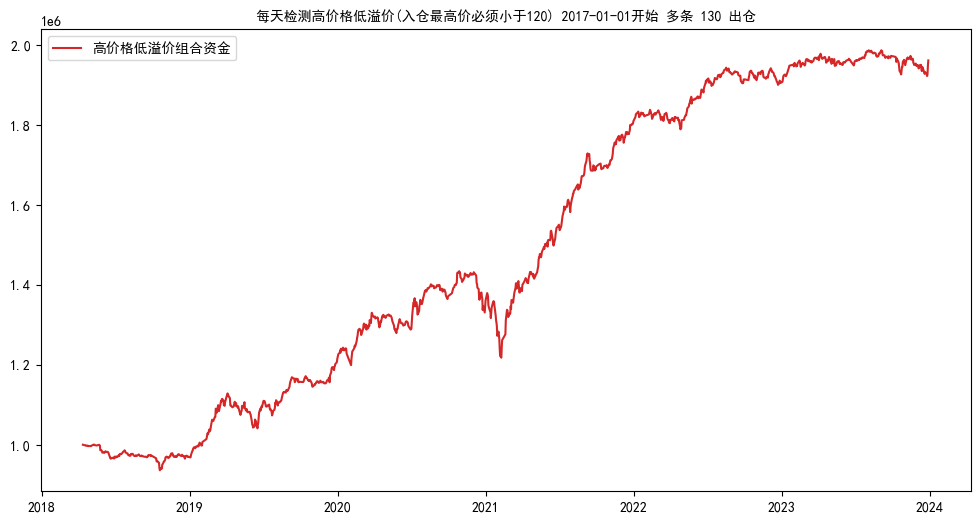

In [71]:
plt.plot(inds_cashs_all_df.loc[:,'cash'], color='tab:red', label='高价格低溢价组合资金')

plt.title('每天检测高价格低溢价(入仓最高价必须小于120) 2017-01-01开始 多条 130 出仓', fontproperties='SimHei')
plt.legend()
plt.show()

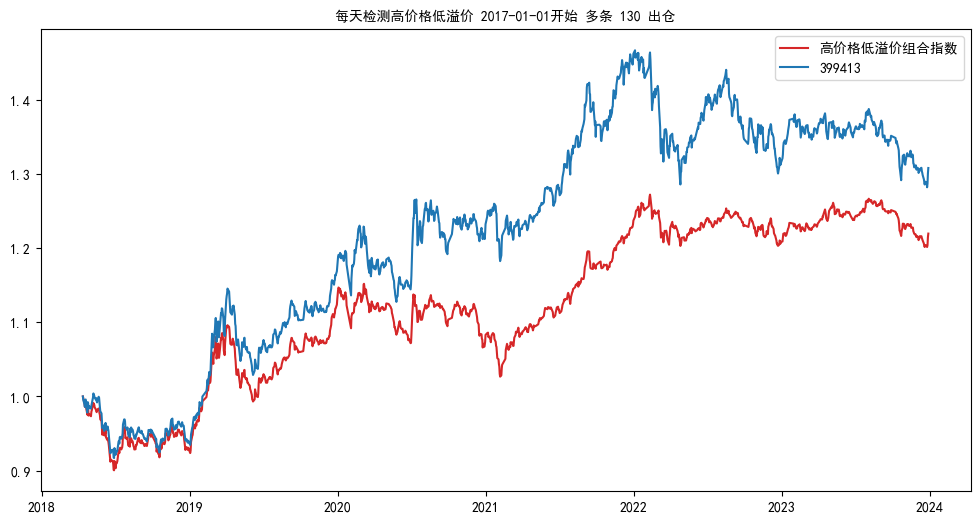

In [70]:
# plt.figure(figsize=(12, 5))
plt.plot(inds_cashs_all_df.loc[:,'ind_per'], color='tab:red', label='高价格低溢价组合指数')
plt.plot(inds_cashs_all_df.loc[:,'close_per'], color='tab:blue', label='399413')

plt.title('每天检测高价格低溢价 2017-01-01开始 多条 130 出仓', fontproperties='SimHei')
plt.legend()
plt.show()

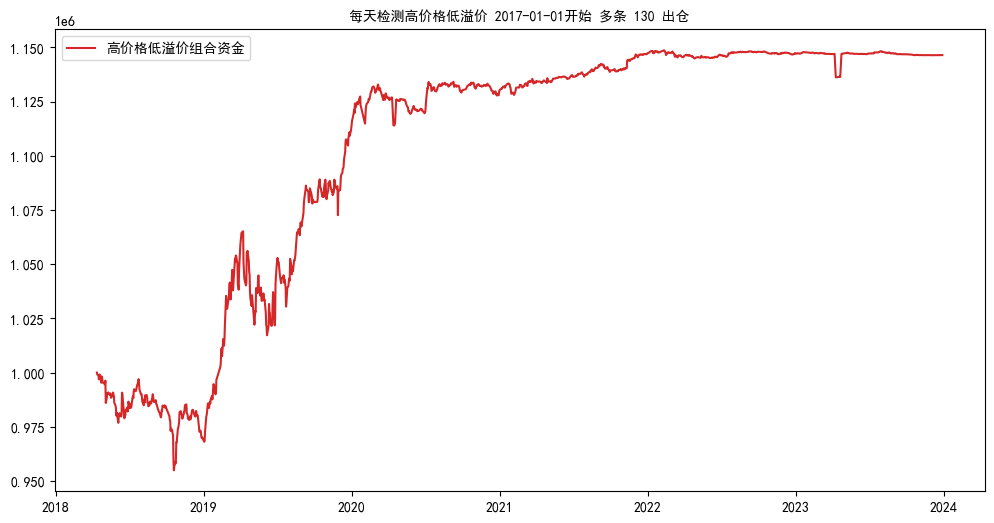

In [41]:
plt.plot(inds_cashs_all_df.loc[:,'cash'], color='tab:red', label='高价格低溢价组合资金')

plt.title('每天检测高价格低溢价 2017-01-01开始 多条 130 出仓', fontproperties='SimHei')
plt.legend()
plt.show()

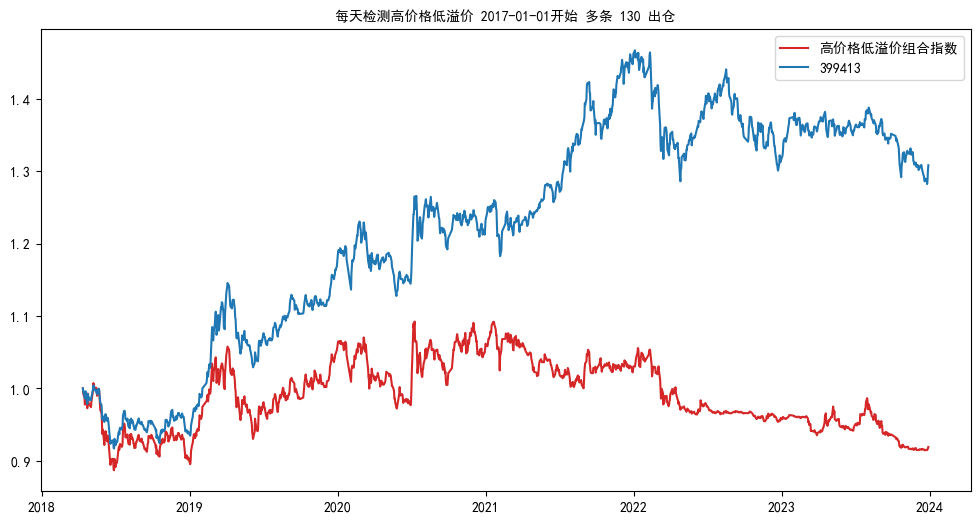

In [42]:
# plt.figure(figsize=(12, 5))
plt.plot(inds_cashs_all_df.loc[:,'ind_per'], color='tab:red', label='高价格低溢价组合指数')
plt.plot(inds_cashs_all_df.loc[:,'close_per'], color='tab:blue', label='399413')

plt.title('每天检测高价格低溢价 2017-01-01开始 多条 130 出仓', fontproperties='SimHei')
plt.legend()
plt.show()

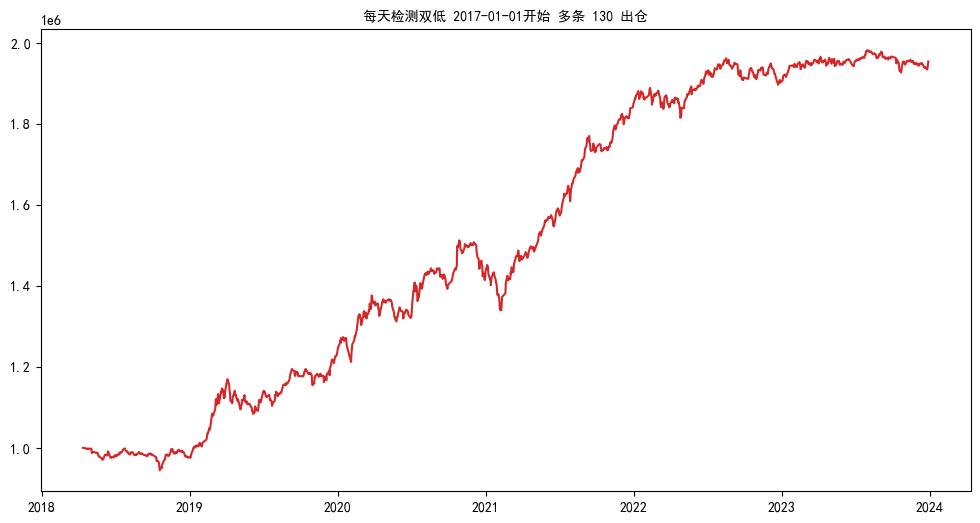

In [83]:
plt.plot(inds_cashs_all_df.loc[:,'cash'], color='tab:red', label='组合持仓每日资金')

plt.title('每天检测双低 2017-01-01开始 多条 130 出仓', fontproperties='SimHei')
# plt.legend()
plt.show()

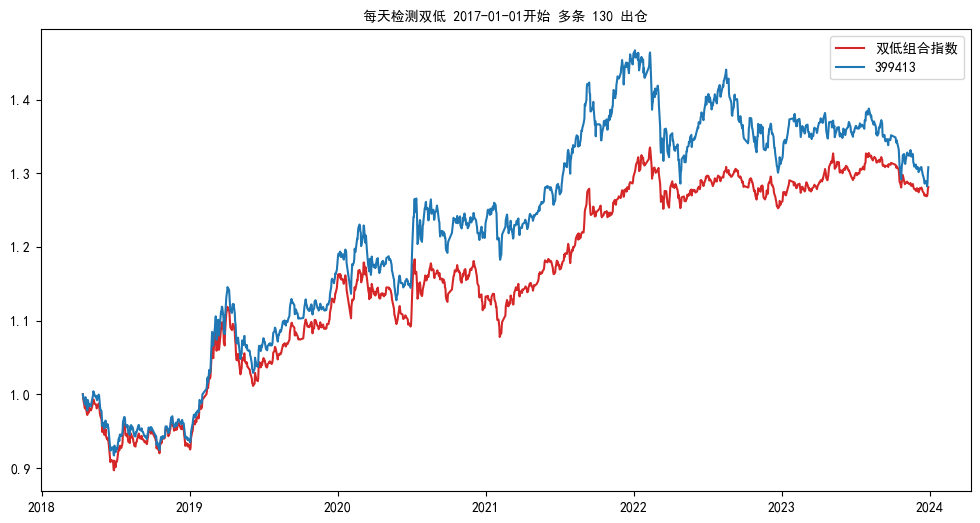

In [84]:
# plt.figure(figsize=(12, 5))
plt.plot(inds_cashs_all_df.loc[:,'ind_per'], color='tab:red', label='双低组合指数')
plt.plot(inds_cashs_all_df.loc[:,'close_per'], color='tab:blue', label='399413')

plt.title('每天检测双低 2017-01-01开始 多条 130 出仓', fontproperties='SimHei')
plt.legend()
plt.show()

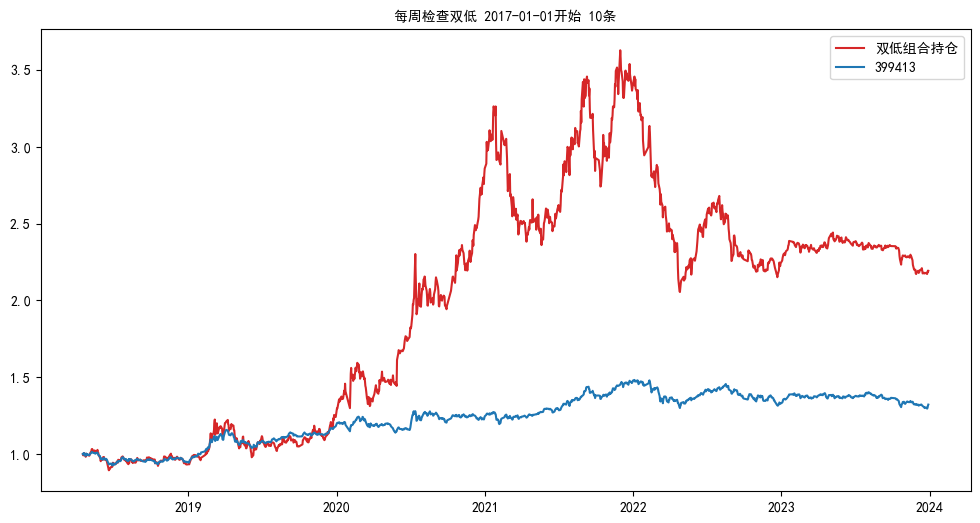

In [44]:
plt.plot(inds_all_df.loc[:,'ind_per'], color='tab:red', label='双低组合持仓')
plt.plot(inds_all_df.loc[:,'close'], color='tab:blue', label='399413')

plt.title('每周检查双低 2017-01-01开始 10条', fontproperties='SimHei')
plt.legend()
plt.show()

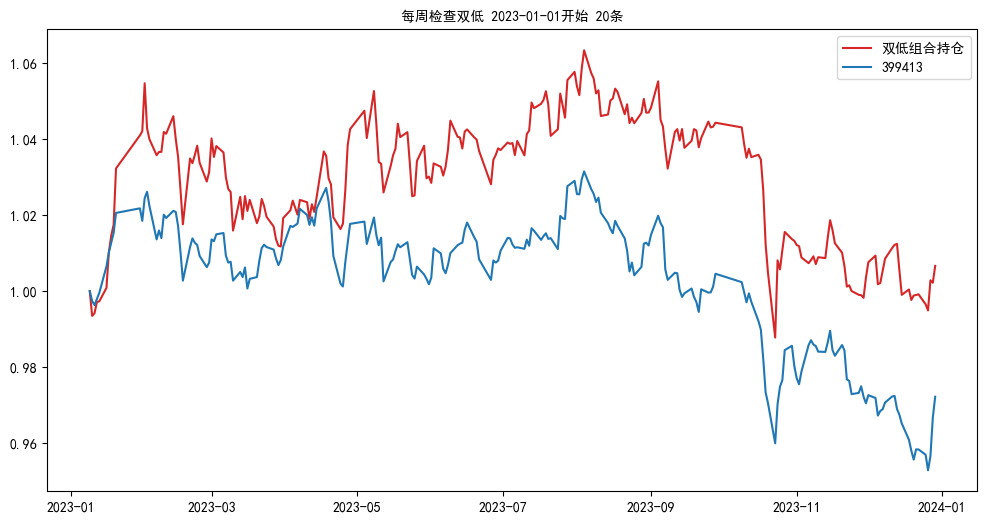

In [33]:
plt.plot(inds_all_df.loc[:,'ind_per'], color='tab:red', label='双低组合持仓')
plt.plot(inds_all_df.loc[:,'close_per'], color='tab:blue', label='399413')

plt.title('每周检查双低 2023-01-01开始 20条', fontproperties='SimHei')
plt.legend()
plt.show()

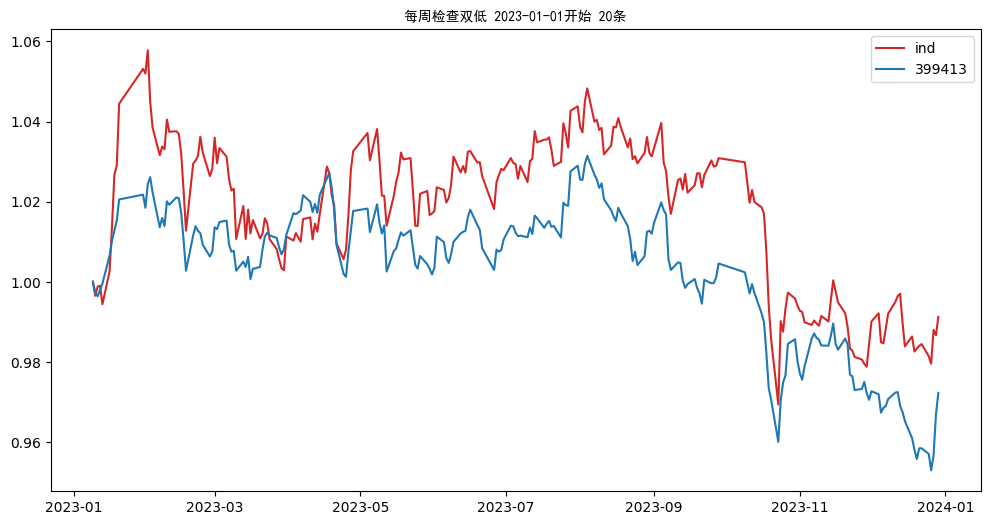

In [38]:
plt.plot(inds_all_df.loc[:,'ind_per'], color='tab:red', label='ind')
plt.plot(inds_all_df.loc[:,'close_per'], color='tab:blue', label='399413')

plt.title('每周检查双低 2023-01-01开始 20条', fontproperties='SimHei')
plt.legend()
plt.show()

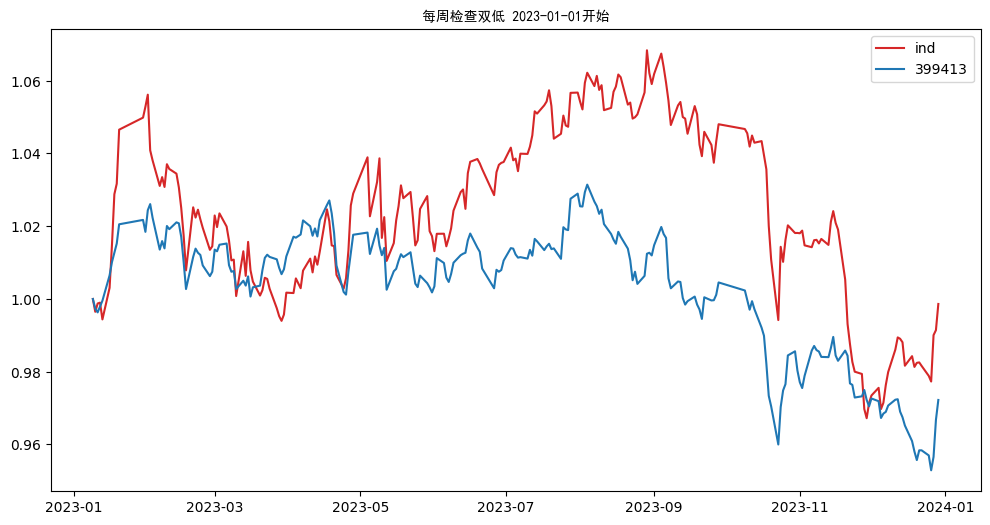

In [52]:
plt.plot(inds_all_df.loc[:,'ind_per'], color='tab:red', label='ind')
plt.plot(inds_all_df.loc[:,'close_per'], color='tab:blue', label='399413')

plt.title('每周检查双低 2023-01-01开始', fontproperties='SimHei')
plt.legend()
plt.show()

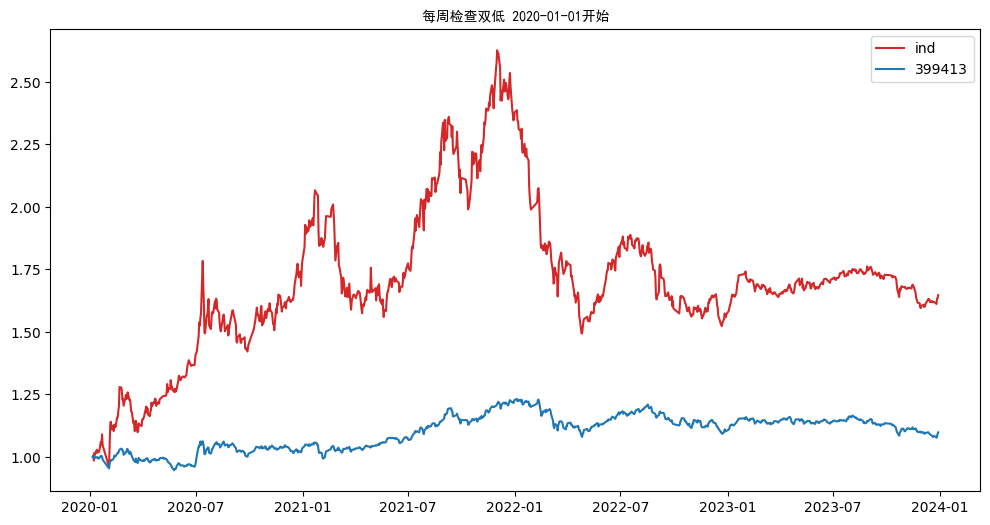

In [40]:
plt.plot(inds_all_df.loc[:,'ind_per'], color='tab:red', label='ind')
plt.plot(inds_all_df.loc[:,'close_per'], color='tab:blue', label='399413')

plt.title('每周检查双低 2020-01-01开始', fontproperties='SimHei')
plt.legend()
plt.show()

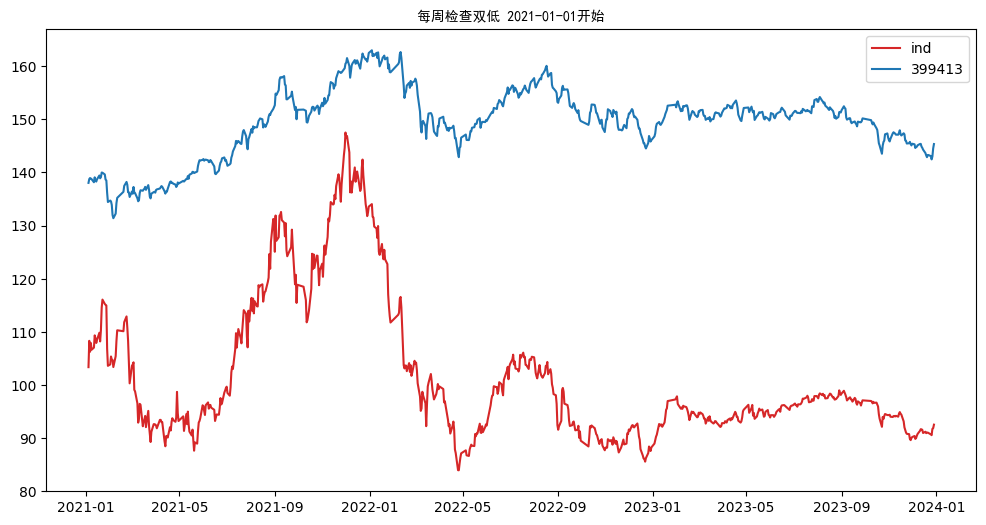

In [172]:
plt.plot(inds_all_df.loc[:,'ind'], color='tab:red', label='ind')
plt.plot(inds_all_df.loc[:,'close'], color='tab:blue', label='399413')

plt.title('每周检查双低 2021-01-01开始', fontproperties='SimHei')
plt.legend()
plt.show()

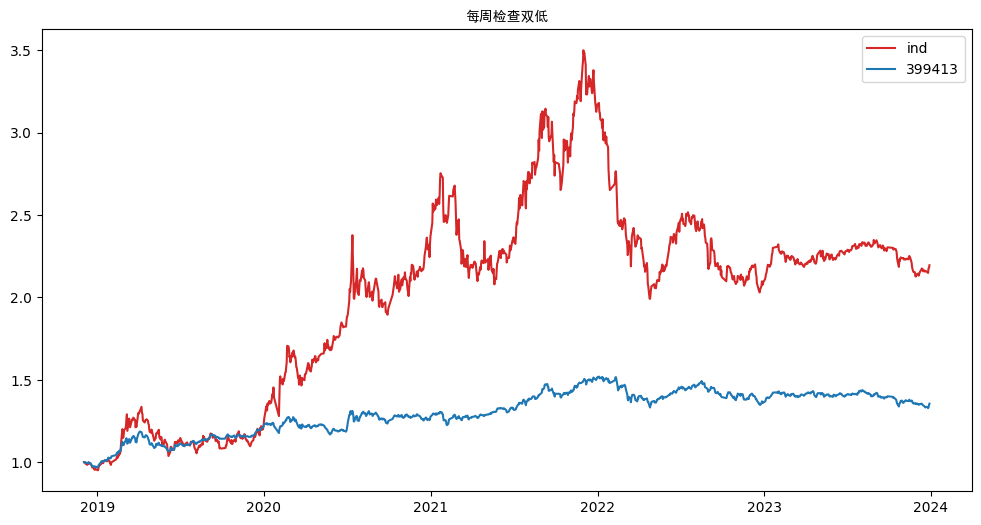

In [165]:
plt.plot(inds_all_df.loc[:,'ind_per'], color='tab:red', label='ind')
plt.plot(inds_all_df.loc[:,'close_per'], color='tab:blue', label='399413')

plt.title('每周检查双低', fontproperties='SimHei')
plt.legend()
plt.show()

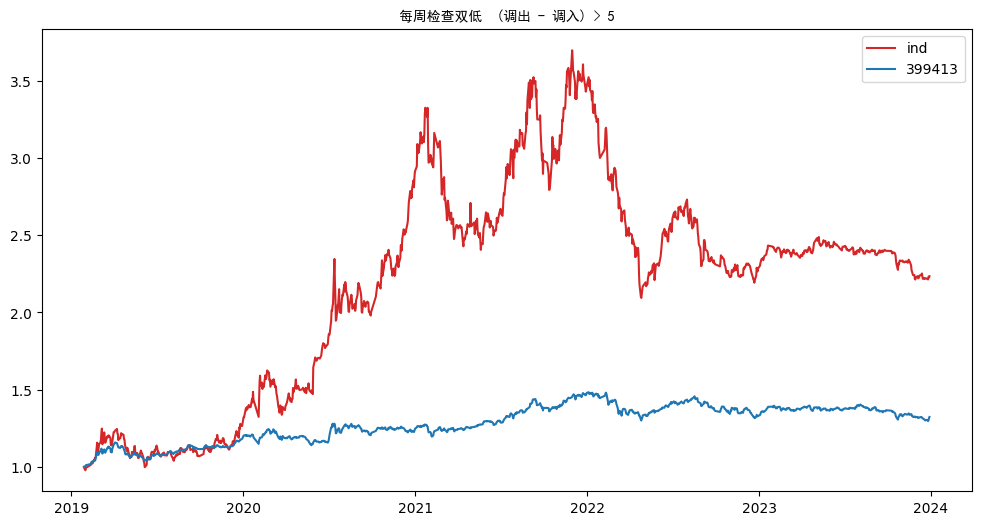

In [161]:
plt.plot(inds_all_df.loc[:,'ind_per'], color='tab:red', label='ind')
plt.plot(inds_all_df.loc[:,'close_per'], color='tab:blue', label='399413')

plt.title('每周检查双低  (调出 - 调入) > 5', fontproperties='SimHei')
plt.legend()
plt.show()

array(['123238', '123237', '127103', '113681', '127102', '111018',
       '127101', '123236', '113069', '123235', '127100', '118046',
       '123234', '127099', '123233', '123232', '127098', '113680',
       '123231', '123230', '127097', '113679', '127096', '123229',
       '123228', '123227', '113678', '127095', '127094', '127093',
       '123226', '123225', '127092', '123224', '123223', '113677',
       '118045', '118044', '123222', '127091', '123221', '113676',
       '123220', '111017', '118043', '113675', '123219', '118042',
       '123218', '110095', '123217', '123216', '123215', '118041',
       '123214', '113068', '123213', '123212', '123210', '123211',
       '113067', '123209', '111016', '118040', '127090', '123208',
       '123207', '113674', '123206', '118039', '110094', '127089',
       '113673', '113672', '118038', '123205', '123204', '113671',
       '111015', '118037', '123202', '123203', '127088', '118036',
       '123200', '123201', '111014', '127087', '127086', '1231

In [55]:
for _, _, f in datetime_range:
    print('%s %s' % (f, f[2:8] in bond_zh_cov_info_ths_df['债券代码'].values))

sh110039.csv True
sh113010.csv False
sh110032.csv False
sh110040.csv True
sh113015.csv True
sz123001.csv False
sh110030.csv False
sz128020.csv True
sz128016.csv True
sz128012.csv False
sh113503.csv True
sz128019.csv True
sh113008.csv False
sz128010.csv False
sh110031.csv False
sh113012.csv True
sh113014.csv True
sz128018.csv True
sh110033.csv False
sh110034.csv False
sh113009.csv False
sz127003.csv False
sz128013.csv False
sh113502.csv True
sh110038.csv True
sz128015.csv True
sz128022.csv True
sh113011.csv True
sz128014.csv True
sz127004.csv True
sh113016.csv True
sh113013.csv True
sz128017.csv True
sz123002.csv True
sz128021.csv True
sz128023.csv True
sz128025.csv True
sz128026.csv True
sh110041.csv True
sz128024.csv True
sh110042.csv True
sh113017.csv True
sz128029.csv True
sz123003.csv True
sz128028.csv True
sz128027.csv True
sz128032.csv True
sz123007.csv True
sz123004.csv True
sz123006.csv True
sz128030.csv True
sz128033.csv True
sz123005.csv True
sh113018.csv True
sz128034.csv Tr

In [44]:
bond_zh_cov_info_ths_df = ak.bond_zh_cov_info_ths()

In [62]:
bond_zh_cov_info_ths_df

,债券代码,债券简称,申购日期,申购代码,原股东配售码,每股获配额,计划发行量,实际发行量,中签公布日,中签号,上市日期,正股代码,正股简称,转股价格,到期时间,中签率
0,123238,卡倍转02,2024-01-11,370863,380863,5.9518,5.2900,5.2900,2024-01-15,0,NaT,300863,卡倍亿,49.01,2030-01-11,0.00081660
1,123237,佳禾转债,2024-01-04,370793,380793,2.9670,10.0400,10.0400,2024-01-08,71389、21389、46389、96389；\r\n246337、746337；\r\n...,NaT,300793,佳禾智能,21.75,2030-01-04,0.00423126
2,127103,东南转债,2024-01-03,072135,082135,1.7411,20.0000,20.0000,2024-01-05,05203、25203、45203、65203、85203、11317；\r\n022753...,NaT,002135,东南网架,5.73,2030-01-03,0.00637623
3,113681,镇洋转债,2023-12-29,754213,753213,1.5170,6.6000,6.6000,2024-01-03,729104、854104、979104、604104、479104、354104、2291...,NaT,603213,镇洋发展,11.74,2029-12-29,0.00098724
4,127102,浙建转债,2023-12-25,072761,082761,0.9247,10.0000,10.0000,2023-12-27,09545、29545、49545、69545、89545；\r\n337469；\r\n9...,2024-01-16,002761,浙江建投,11.01,2029-12-25,0.00513989
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
820,128015,久其转债,2017-06-08,072279,082279,1.1084,7.8000,7.8000,2017-06-14,0,2017-06-27,002279,久其软件,5.00,2023-06-08,2.38141745
821,127004,模塑转债,2017-06-02,070700,080700,1.1344,8.1366,8.1366,2017-06-08,0,2017-06-26,000700,模塑科技,7.24,2023-06-02,0.50864100
822,128014,永东转债,2017-04-17,072753,082753,2.2965,3.4000,3.4000,2017-04-21,0,2017-05-12,002753,永东股份,9.28,2023-04-17,1.32286600
823,113012,骆驼转债,2017-03-24,783311,764311,0.8450,7.1700,7.1700,2017-03-30,0,2017-04-13,601311,骆驼股份,9.86,2023-03-24,0.15814823


In [69]:
bond_zh_cov_info_ths_df.loc[bond_zh_cov_info_ths_df['债券代码'] == '127004', '实际发行量'].iloc[0]

8.1366